In [1]:
print('hi')

[1] "hi"


In [ ]:
install.packages("faraway", repos = "https://cloud.r-project.org")

also installing the dependencies ‘rbibutils’, ‘Matrix’, ‘MASS’, ‘Rdpack’, ‘boot’, ‘lattice’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘Rcpp’, ‘RcppEigen’, ‘lme4’, ‘nlme’


Warning message in install.packages("faraway", repos = "https://cloud.r-project.org"):
“installation of package ‘nloptr’ had non-zero exit status”
Warning message in install.packages("faraway", repos = "https://cloud.r-project.org"):
“installation of package ‘Matrix’ had non-zero exit status”
Warning message in install.packages("faraway", repos = "https://cloud.r-project.org"):
“installation of package ‘Rdpack’ had non-zero exit status”


In [3]:
library(faraway)

In [13]:
data(sat)
head(sat)

,expend,ratio,salary,takers,verbal,math,total
,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>
Alabama,4.405,17.2,31.144,8,491,538,1029
Alaska,8.963,17.6,47.951,47,445,489,934
Arizona,4.778,19.3,32.175,27,448,496,944
Arkansas,4.459,17.1,28.934,6,482,523,1005
California,4.992,24.0,41.078,45,417,485,902
Colorado,5.443,18.4,34.571,29,462,518,980


In [15]:
?sat

sat {faraway},R Documentation


In [14]:
library(faraway)
data(sat)

model <- lm(total ~ expend + salary + ratio + takers,
            data = sat)

summary(model)


Call:
lm(formula = total ~ expend + salary + ratio + takers, data = sat)

Residuals:
    Min      1Q  Median      3Q     Max 
-90.531 -20.855  -1.746  15.979  66.571 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 1045.9715    52.8698  19.784  < 2e-16 ***
expend         4.4626    10.5465   0.423    0.674    
salary         1.6379     2.3872   0.686    0.496    
ratio         -3.6242     3.2154  -1.127    0.266    
takers        -2.9045     0.2313 -12.559 2.61e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 32.7 on 45 degrees of freedom
Multiple R-squared:  0.8246,	Adjusted R-squared:  0.809 
F-statistic: 52.88 on 4 and 45 DF,  p-value: < 2.2e-16


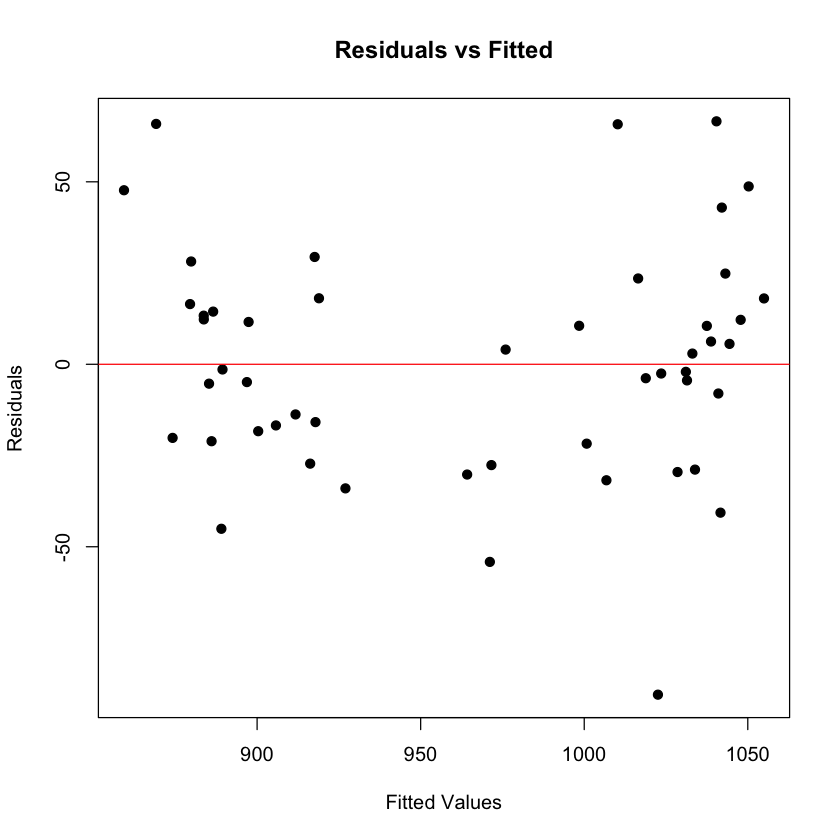

In [16]:
plot(fitted(model), residuals(model),
     xlab = "Fitted Values",
     ylab = "Residuals",
     main = "Residuals vs Fitted",
     pch = 19)

abline(h = 0, col = "red")

# Residuals:
Eye ball test says it's normally distributed. E(residuals) = 0.

In [17]:
variance_model <- lm(sqrt(abs(residuals(model))) ~ fitted(model))

summary(variance_model)


Call:
lm(formula = sqrt(abs(residuals(model))) ~ fitted(model))

Residuals:
    Min      1Q  Median      3Q     Max 
-3.3097 -1.2366 -0.2234  0.9929  5.0337 

Coefficients:
                Estimate Std. Error t value Pr(>|t|)
(Intercept)    4.6484524  4.0660807   1.143    0.259
fitted(model) -0.0001637  0.0041994  -0.039    0.969

Residual standard error: 1.997 on 48 degrees of freedom
Multiple R-squared:  3.166e-05,	Adjusted R-squared:  -0.0208 
F-statistic: 0.00152 on 1 and 48 DF,  p-value: 0.9691


1)

Using the sat dataset, fit a model with the total SAT score as the response and expend,
salary, ratio and takers as predictors. Perform regression diagnostics on this model to
answer the following questions. Display any plots that are relevent. Do not provide
any plots about which you have nothing to say

(a) Check the constant variance assumption for the errors.

(b) Check the normality assumption.

(c) Check for large leverage points.

(d) Check for outliers.

(e) Check for influential points.

(f) Check the structure of the relationship between the predictors and the response

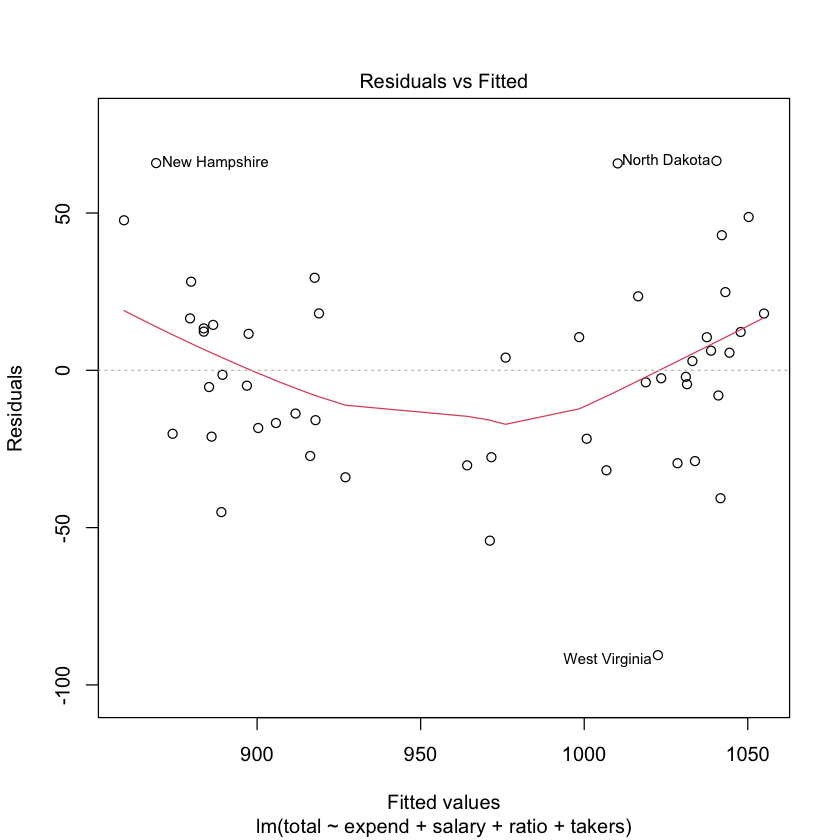

In [21]:
#a)
plot(model, which = 1)

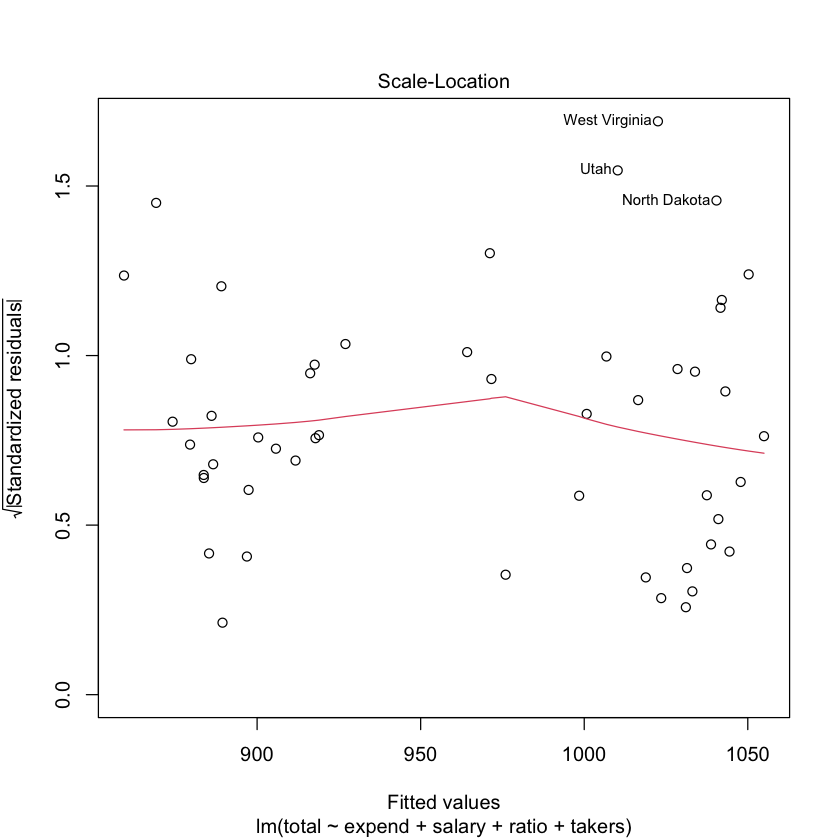

In [23]:
plot(model, which = 3)

Neither plots show strong signs of non-constant variance (heteroscedasiticity);
Residual vs. fitted plot diagram doesn't show huge differences given the sample.
The scale-location plot shows the spread also shows consistent spread of square-rooted / abs of residuals.

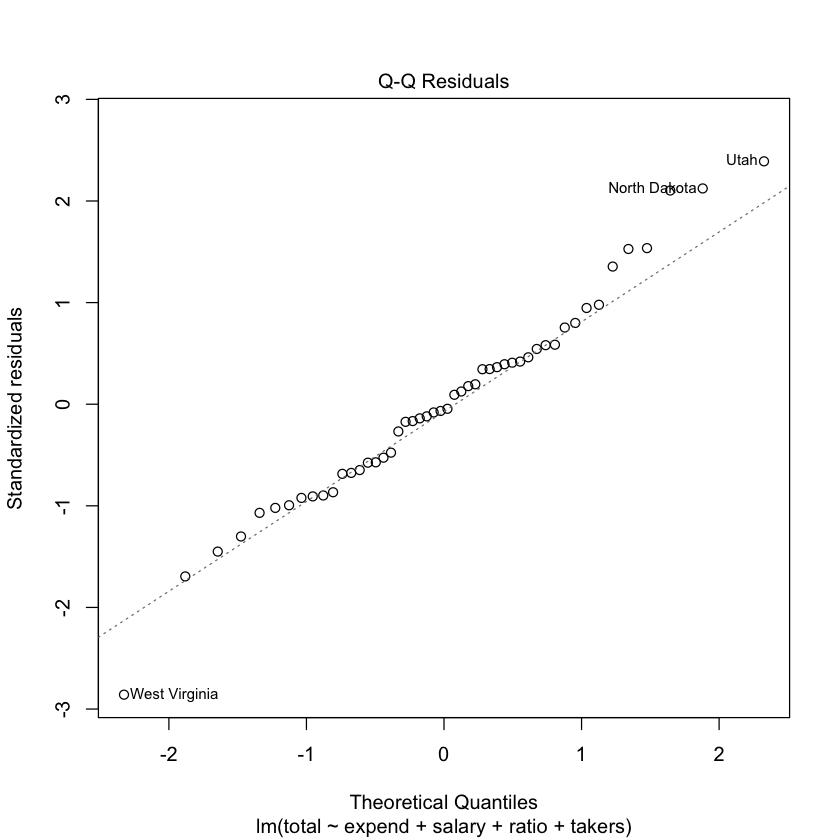

In [24]:
#b) checking for normality
plot(model, which = 2)


In [25]:
shapiro.test(residuals(model))


	Shapiro-Wilk normality test

data:  residuals(model)
W = 0.97691, p-value = 0.4304


The Q-Q plot shows that it ROUGHLY follows the y=x line, however it seems to be over the fitted line by a bit. Given the shapiro-wilk test states that the null is that it does follow a normal distribution and the alternative being that it does not, the p-value of 0.43 > 0.05, we fail to reject the null, we fail to reject that it does not follow the normal distribution.

In [26]:
# c)
lev <- hatvalues(model)

n <- nrow(sat)           # Number of observations (50)
p <- length(coef(model)) # Number of coefficients (5)

cutoff <- 2*p/n

# Identify high-leverage points
lev[lev > cutoff]

California Connecticut  New Jersey        Utah 
  0.2821179   0.2254519   0.2220978   0.2921128

The large leverage points are the states:
California, Conncticut, New Jersey, Utah.

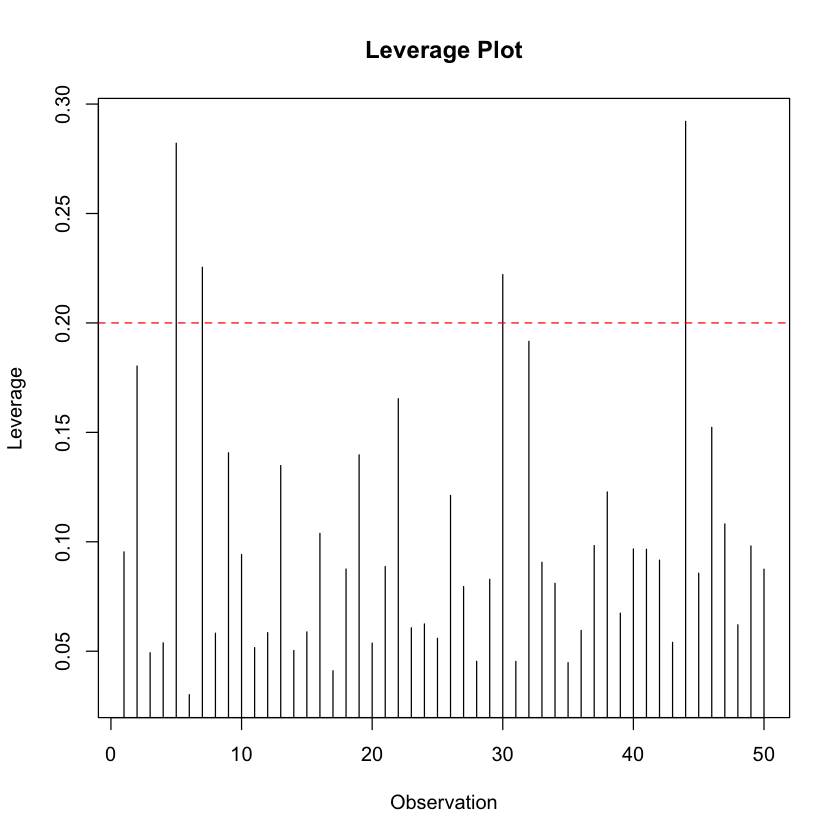

In [27]:
plot(lev, type = "h",
     main = "Leverage Plot",
     xlab = "Observation",
     ylab = "Leverage")

abline(h = cutoff, col = "red", lty = 2)

In [30]:
#d
res <- residuals(model)
std <- sd(res)

res[abs(res) > 2*std]

New Hampshire  North Dakota          Utah West Virginia 
     65.86530      66.57129      65.76608     -90.53142

The outliers are those with huge residuals or those far away from the sample mean. Those states are: New Hampshire, North Dakota, Utah, and West Virginia.

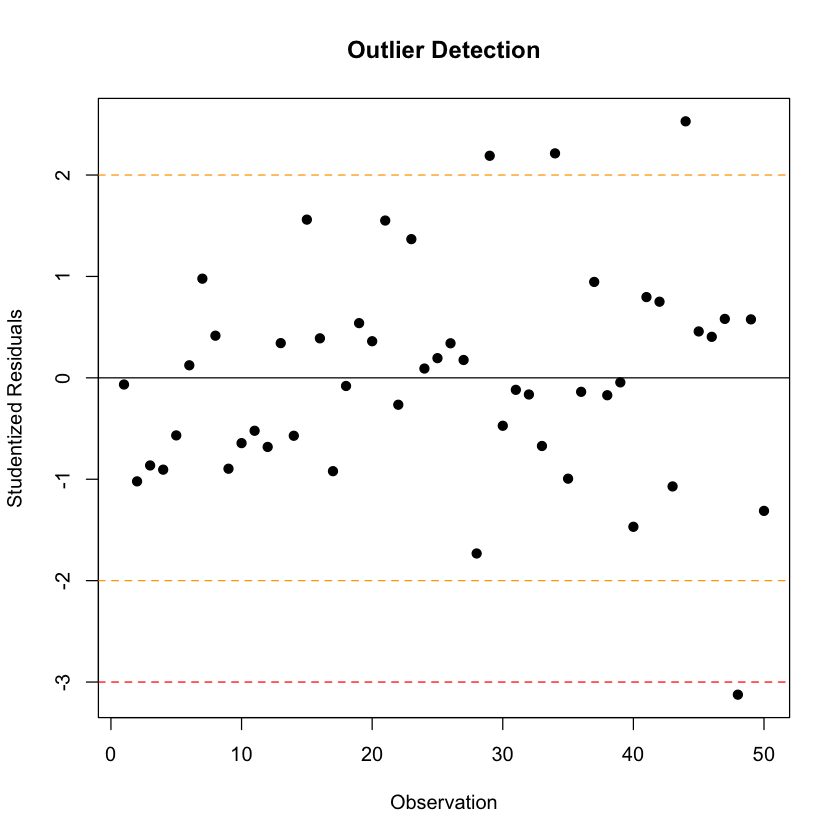

In [29]:
plot(stud, pch = 19,
     xlab = "Observation",
     ylab = "Studentized Residuals",
     main = "Outlier Detection")

abline(h = 0)
abline(h = c(-2, 2), col = "orange", lty = 2)
abline(h = c(-3, 3), col = "red", lty = 2)

In [31]:
# e) 

cook <- cooks.distance(model)

cutoff <- 4/nrow(sat)

# Identify potentially influential points
cook[cook > cutoff]

Utah West Virginia 
    0.4715287     0.1081395

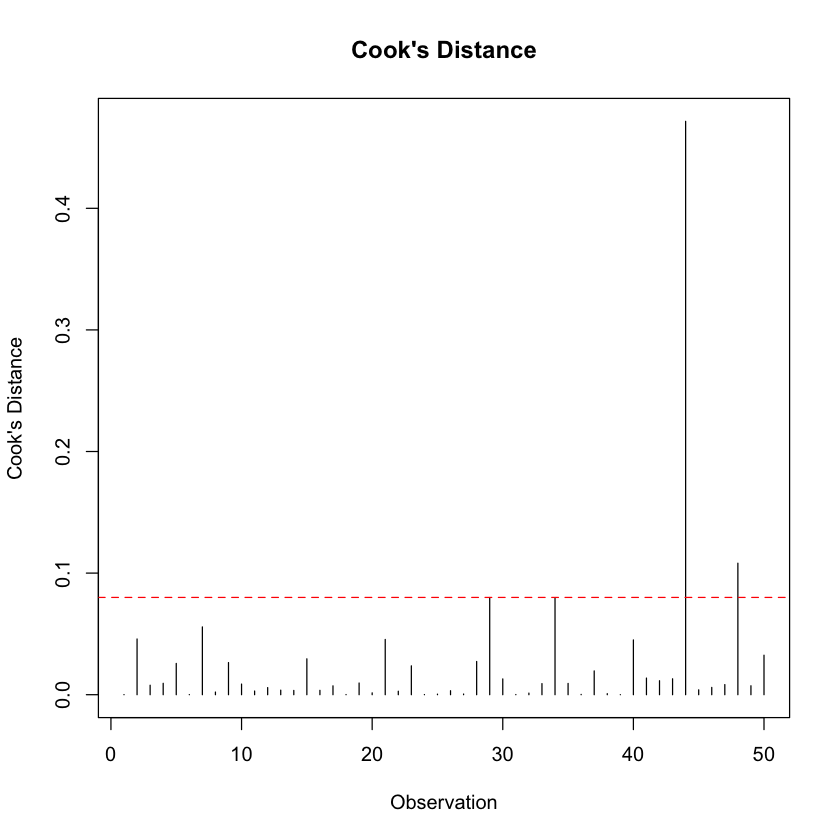

In [32]:
plot(cook, type = "h",
     main = "Cook's Distance",
     xlab = "Observation",
     ylab = "Cook's Distance")

abline(h = cutoff, col = "red", lty = 2)

Potential influential points are: Utah and West Virginia. This means if they were removed, it would potentially drastically change our line of best fit.

In [34]:
#f) 
summary(model)



Call:
lm(formula = total ~ expend + salary + ratio + takers, data = sat)

Residuals:
    Min      1Q  Median      3Q     Max 
-90.531 -20.855  -1.746  15.979  66.571 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 1045.9715    52.8698  19.784  < 2e-16 ***
expend         4.4626    10.5465   0.423    0.674    
salary         1.6379     2.3872   0.686    0.496    
ratio         -3.6242     3.2154  -1.127    0.266    
takers        -2.9045     0.2313 -12.559 2.61e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 32.7 on 45 degrees of freedom
Multiple R-squared:  0.8246,	Adjusted R-squared:  0.809 
F-statistic: 52.88 on 4 and 45 DF,  p-value: < 2.2e-16


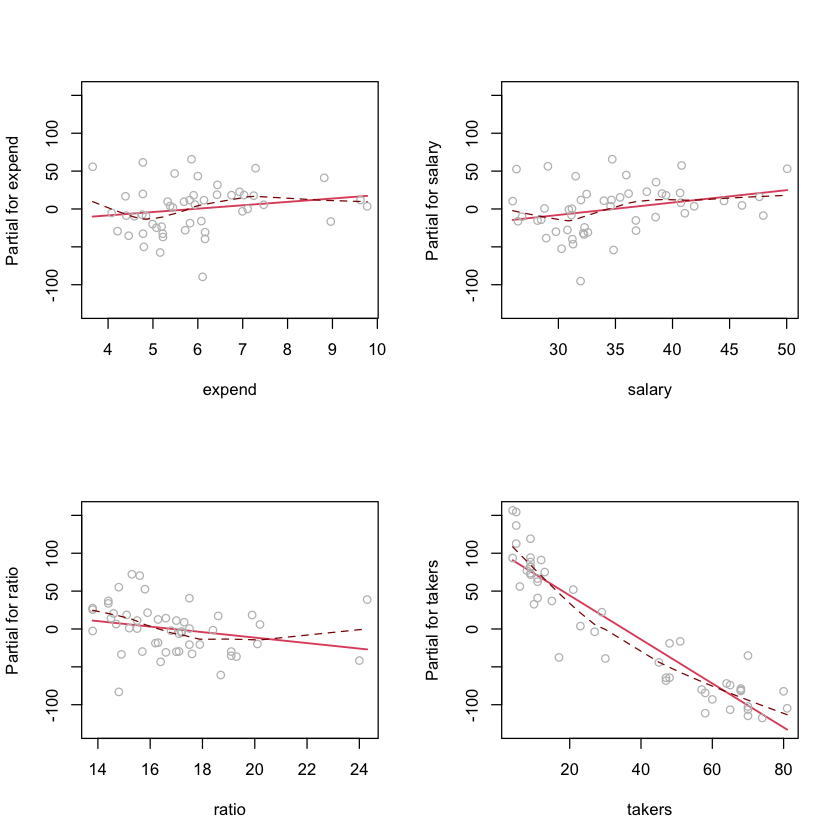

In [35]:
par(mfrow = c(2, 2))
termplot(model, partial.resid = TRUE, smooth = panel.smooth)

No p-values suggest the weak features. Features and their partial residuals follow a linear structure, some more stronger/linear than others. Takers seems to be the tightest.

# 2)

Using the teengamb dataset, fit a model with gamble as the response and the other
variables as predictors. Answer the questions posed in the previous question

In [37]:
library(faraway)
data(teengamb)
head(teengamb)

,sex,status,income,verbal,gamble
,<int>,<int>,<dbl>,<int>,<dbl>
1,1,51,2.00,8,0.0
2,1,28,2.50,8,0.0
3,1,37,2.00,6,0.0
4,1,28,7.00,4,7.3
5,1,65,2.00,8,19.6
6,1,61,3.47,6,0.1


In [38]:
?teengamb

teengamb {faraway},R Documentation


In [41]:
model <- lm(gamble ~ sex + status + income + verbal,
            data = teengamb)

summary(model)


Call:
lm(formula = gamble ~ sex + status + income + verbal, data = teengamb)

Residuals:
    Min      1Q  Median      3Q     Max 
-51.082 -11.320  -1.451   9.452  94.252 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)  22.55565   17.19680   1.312   0.1968    
sex         -22.11833    8.21111  -2.694   0.0101 *  
status        0.05223    0.28111   0.186   0.8535    
income        4.96198    1.02539   4.839 1.79e-05 ***
verbal       -2.95949    2.17215  -1.362   0.1803    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 22.69 on 42 degrees of freedom
Multiple R-squared:  0.5267,	Adjusted R-squared:  0.4816 
F-statistic: 11.69 on 4 and 42 DF,  p-value: 1.815e-06


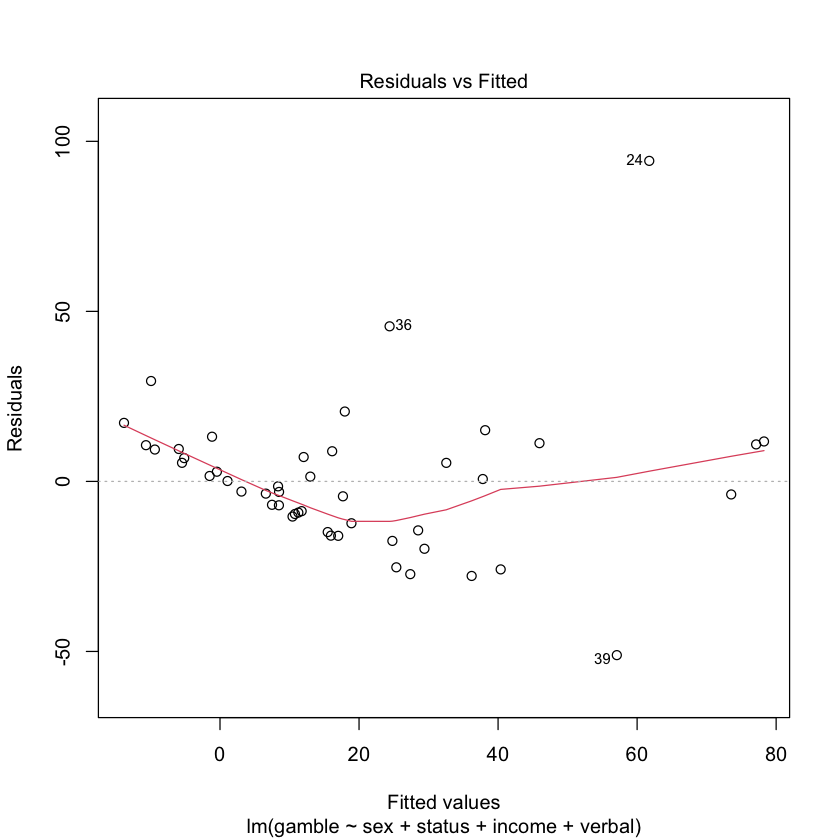

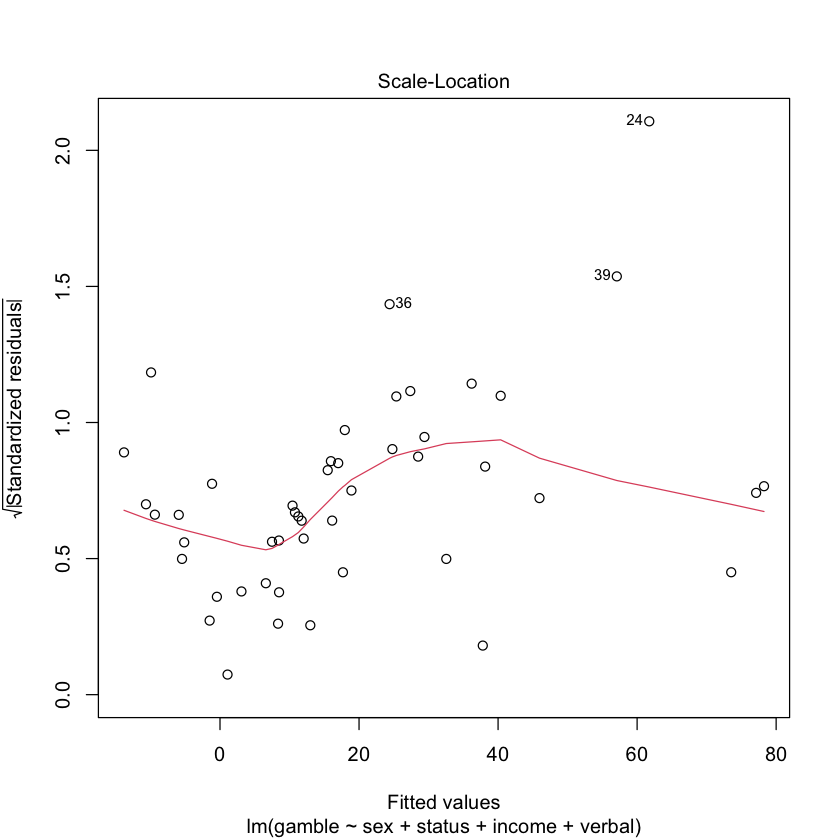

In [42]:
#a)
plot(model, which = 1)
plot(model, which = 3)

(a) Check the constant variance assumption for the errors.
(b) Check the normality assumption.
(c) Check for large leverage points.
(d) Check for outliers.
(e) Check for influential points.
(f) Check the structure of the relationship between the predictors and the response.


Given the non-linearity of fitted vs residuals and also the spread of a hanful of outliers, I believe based on just looking at the plots that constant variance assumptions for error does not exist here.

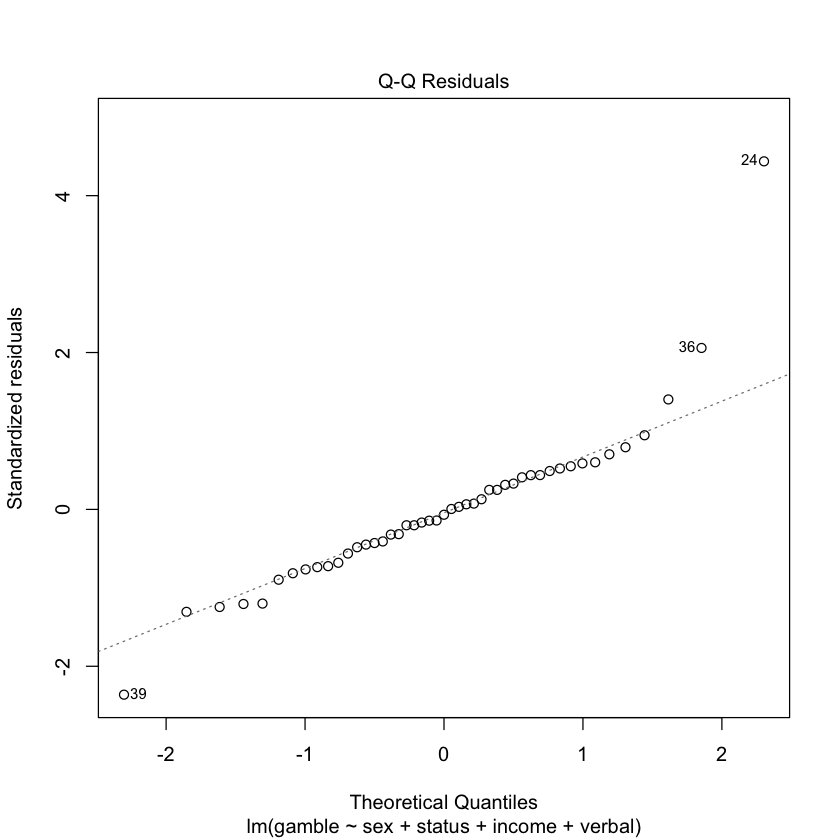

In [43]:
plot(model, which =2)

In [44]:
shapiro.test(residuals(model))


	Shapiro-Wilk normality test

data:  residuals(model)
W = 0.86839, p-value = 8.16e-05


#b)
Given how low the p-value, we reject the null, or evidence against normality, and the Q-Q plot shows that it follows the line linearly. 

In [45]:
# c)
lev <- hatvalues(model)

n <- nrow(sat)           # Number of observations (50)
p <- length(coef(model)) # Number of coefficients (5)

cutoff <- 2*p/n

# Identify high-leverage points
lev[lev > cutoff]

31        33        35        42 
0.2395031 0.2213439 0.3118029 0.3016088

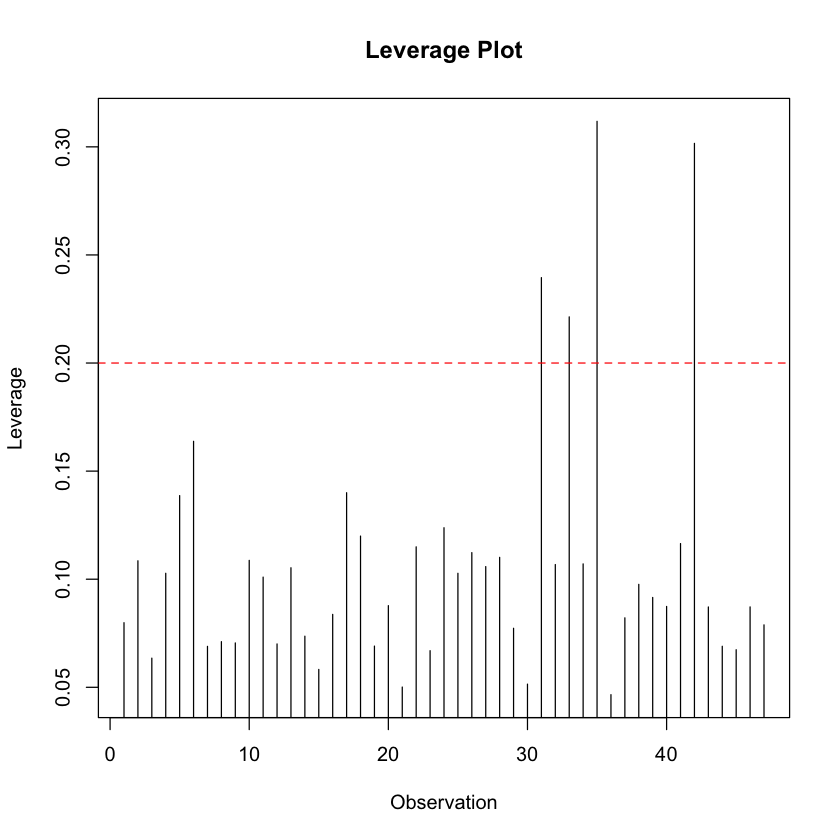

In [46]:
plot(lev, type = "h",
     main = "Leverage Plot",
     xlab = "Observation",
     ylab = "Leverage")

abline(h = cutoff, col = "red", lty = 2)

These individuals show high leverage points

In [47]:
#d
res <- residuals(model)
std <- sd(res)

res[abs(res) > 2*std]

24        36        39 
 94.25222  45.60513 -51.08241

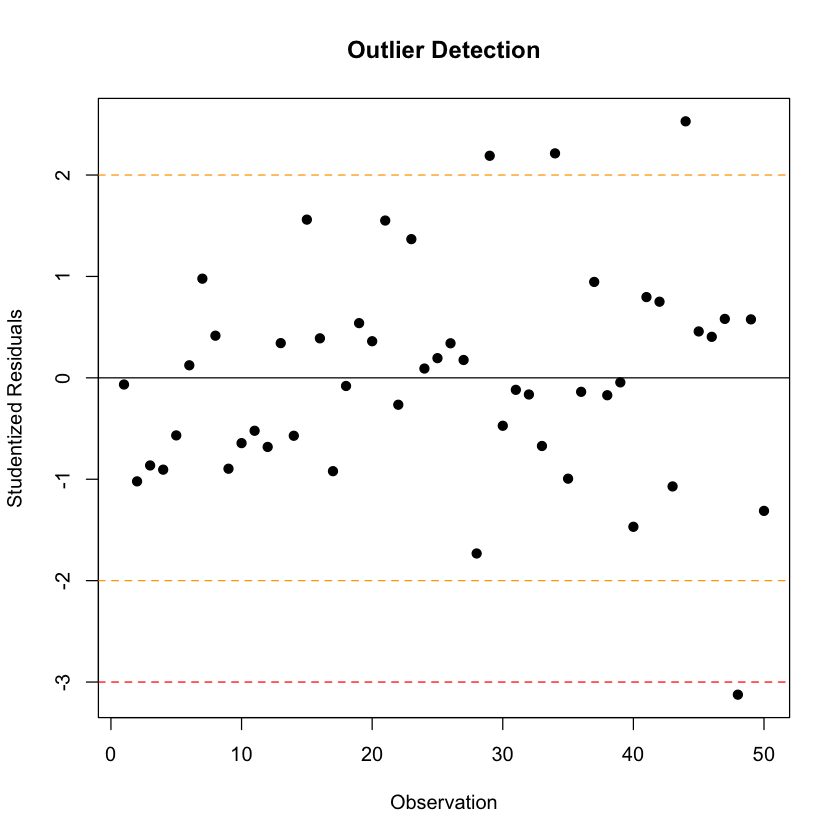

In [48]:
plot(stud, pch = 19,
     xlab = "Observation",
     ylab = "Studentized Residuals",
     main = "Outlier Detection")

abline(h = 0)
abline(h = c(-2, 2), col = "orange", lty = 2)
abline(h = c(-3, 3), col = "red", lty = 2)

Individual gamblers 24,36, and 39 are outliers as they stray the furthest from the mean.

In [49]:
# e) 

cook <- cooks.distance(model)

cutoff <- 4/nrow(sat)

# Identify potentially influential points
cook[cook > cutoff]

24        39 
0.5565011 0.1124498

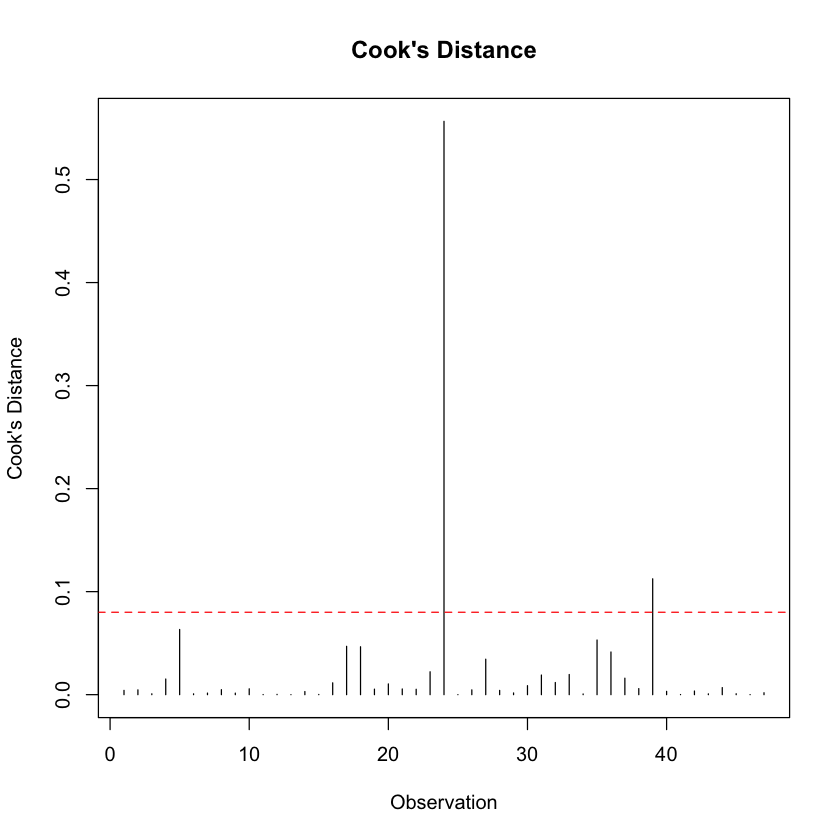

In [50]:
plot(cook, type = "h",
     main = "Cook's Distance",
     xlab = "Observation",
     ylab = "Cook's Distance")

abline(h = cutoff, col = "red", lty = 2)

Indiviudals 24 and 39 are influential points, or points ST if they were to be removed, it would highly influence our line of best fit.

In [51]:
summary(model)


Call:
lm(formula = gamble ~ sex + status + income + verbal, data = teengamb)

Residuals:
    Min      1Q  Median      3Q     Max 
-51.082 -11.320  -1.451   9.452  94.252 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)  22.55565   17.19680   1.312   0.1968    
sex         -22.11833    8.21111  -2.694   0.0101 *  
status        0.05223    0.28111   0.186   0.8535    
income        4.96198    1.02539   4.839 1.79e-05 ***
verbal       -2.95949    2.17215  -1.362   0.1803    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 22.69 on 42 degrees of freedom
Multiple R-squared:  0.5267,	Adjusted R-squared:  0.4816 
F-statistic: 11.69 on 4 and 42 DF,  p-value: 1.815e-06


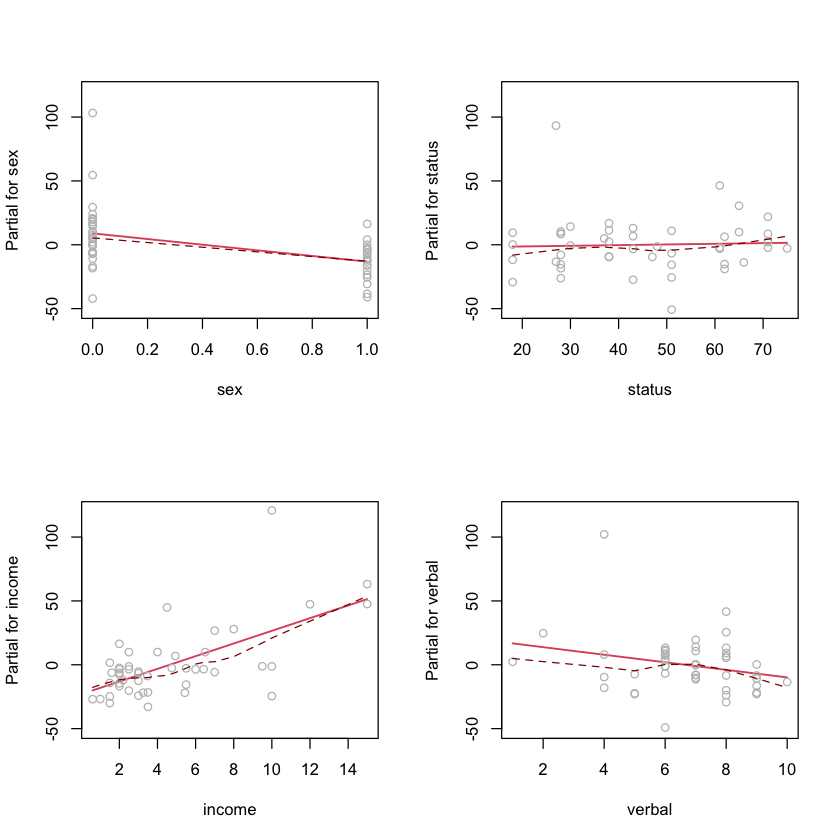

In [52]:
par(mfrow = c(2, 2))
termplot(model, partial.resid = TRUE, smooth = panel.smooth)

#f
It looks roughly linear with an eyeball test. Verbal and income showing some huge outliers.

# 2) Morty

In [65]:
df <- read.csv("housing.txt",
               header = TRUE,
               sep = ",",
               quote = "",
               na.strings = "NA")

dim(df)
head(df)

[1] 1460   81

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,⋯,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
,<int>,<int>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<int>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<chr>,<int>
1,1,60,RL,65,8450,Pave,NA,Reg,Lvl,AllPub,⋯,0,NA,NA,NA,0,2,2008,WD,Normal,208500
2,2,20,RL,80,9600,Pave,NA,Reg,Lvl,AllPub,⋯,0,NA,NA,NA,0,5,2007,WD,Normal,181500
3,3,60,RL,68,11250,Pave,NA,IR1,Lvl,AllPub,⋯,0,NA,NA,NA,0,9,2008,WD,Normal,223500
4,4,70,RL,60,9550,Pave,NA,IR1,Lvl,AllPub,⋯,0,NA,NA,NA,0,2,2006,WD,Abnorml,140000
5,5,60,RL,84,14260,Pave,NA,IR1,Lvl,AllPub,⋯,0,NA,NA,NA,0,12,2008,WD,Normal,250000
6,6,50,RL,85,14115,Pave,NA,IR1,Lvl,AllPub,⋯,0,NA,MnPrv,Shed,700,10,2009,WD,Normal,143000


In [66]:
#library(faraway)
#data(sat)

# Keep only numerical columns
continuous.data <- df[, sapply(df, is.numeric)]

# Remove ID
continuous.data$Id <- NULL

# Fit regression
model <- lm(SalePrice ~ ., data = continuous.data)

summary(model)


Call:
lm(formula = SalePrice ~ ., data = continuous.data)

Residuals:
    Min      1Q  Median      3Q     Max 
-442865  -16873   -2581   14998  318042 

Coefficients: (2 not defined because of singularities)
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)   -3.232e+05  1.701e+06  -0.190 0.849317    
MSSubClass    -2.005e+02  3.449e+01  -5.814 8.03e-09 ***
LotFrontage   -1.161e+02  6.124e+01  -1.896 0.058203 .  
LotArea        5.454e-01  1.573e-01   3.466 0.000548 ***
OverallQual    1.870e+04  1.478e+03  12.646  < 2e-16 ***
OverallCond    5.227e+03  1.367e+03   3.824 0.000139 ***
YearBuilt      3.170e+02  8.762e+01   3.617 0.000311 ***
YearRemodAdd   1.206e+02  8.661e+01   1.392 0.164174    
MasVnrArea     3.160e+01  7.006e+00   4.511 7.15e-06 ***
BsmtFinSF1     1.739e+01  5.835e+00   2.980 0.002947 ** 
BsmtFinSF2     8.362e+00  8.763e+00   0.954 0.340205    
BsmtUnfSF      5.006e+00  5.275e+00   0.949 0.342890    
TotalBsmtSF           NA         NA      NA       

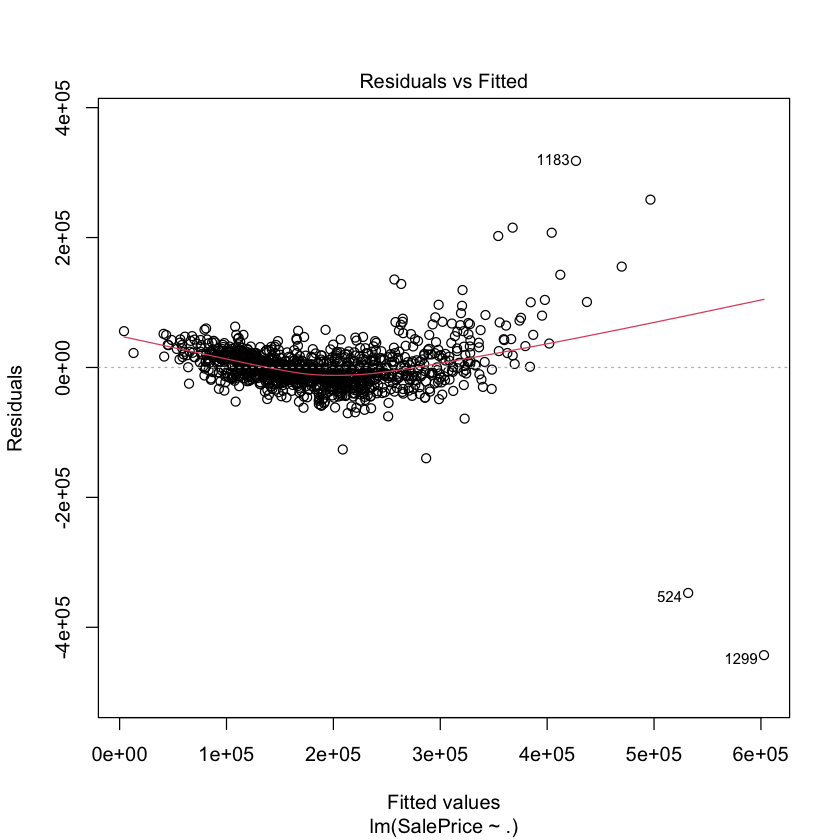

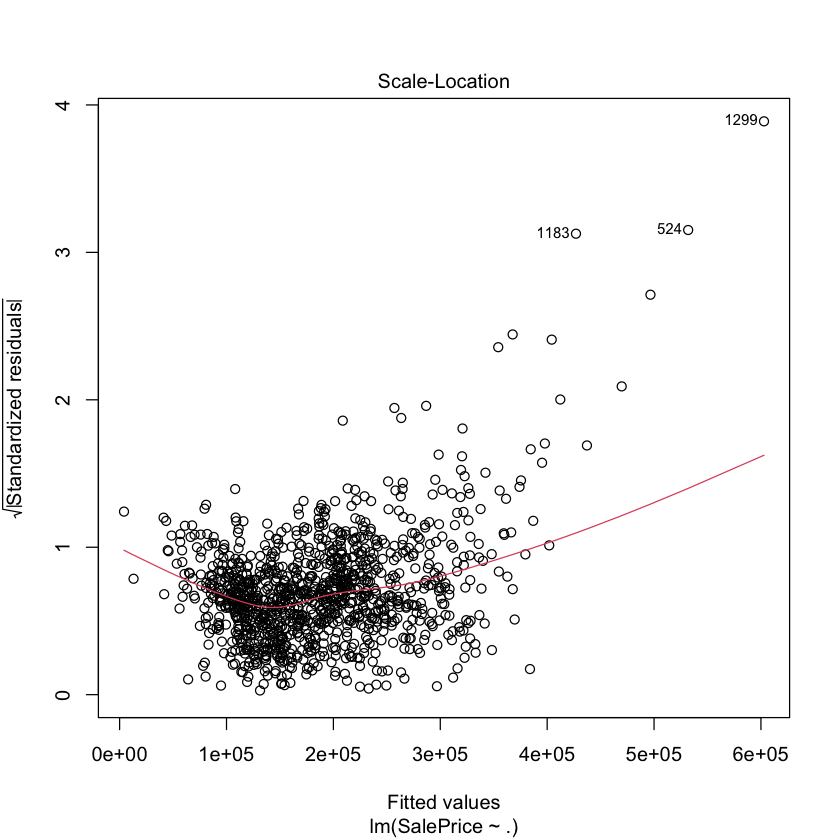

In [67]:
plot(model, which = 1)
plot(model, which = 3) #a


	Shapiro-Wilk normality test

data:  residuals(model)
W = 0.75585, p-value < 2.2e-16


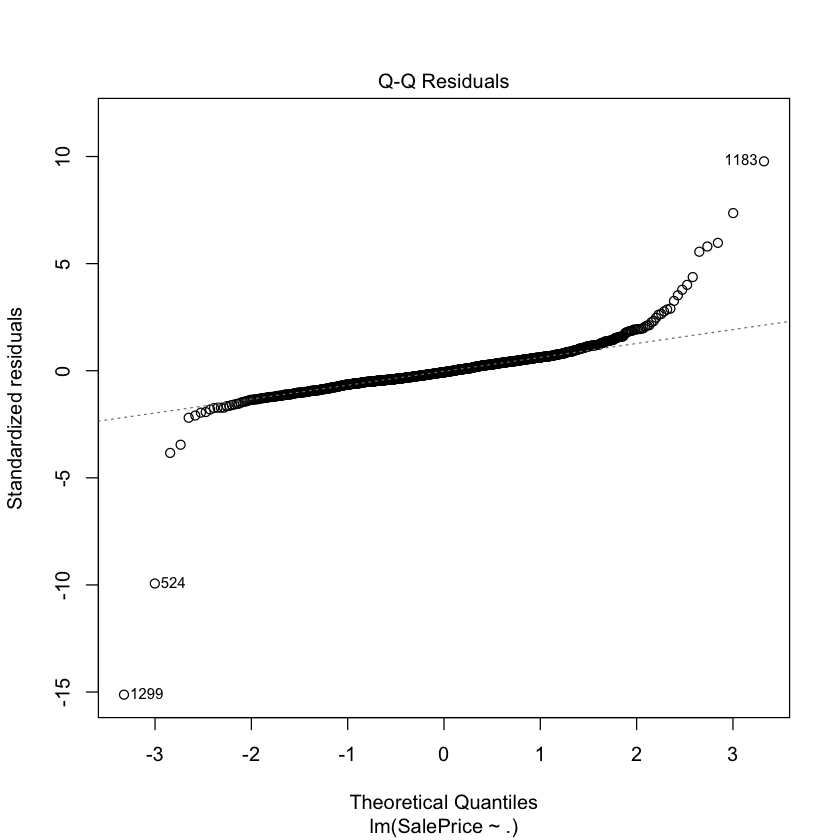

In [68]:
# b
plot(model, which = 2)
shapiro.test(residuals(model))

In [75]:
#c
lev <- hatvalues(model)

n <- nobs(model)
p <- model$rank

cutoff <- 2*p/n

#lev[lev > cutoff]
head(sort(lev, decreasing = TRUE), 10)
#larget leverage values

314      1299      1387       198       811       206      1458       186 
0.6812316 0.3662975 0.3043883 0.3007495 0.2903667 0.2676608 0.2378132 0.2319888 
     1171      1183 
0.2280208 0.2177934

In [76]:
# most influential points
cook <- cooks.distance(model)

cutoff <- 4/n

cook[cook > cutoff]

4           6           9          71         179         186 
0.004948676 0.004466821 0.005420627 0.007062532 0.013065076 0.052848830 
        206         232         279         298         314         379 
0.004014237 0.006873506 0.005147497 0.004861527 0.004122354 0.004572319 
        441         524         589         592         609         633 
0.030926657 0.304228042 0.004987929 0.004183232 0.004527507 0.004461786 
        663         665         689         692         717         770 
0.004022102 0.009747127 0.005628069 0.151735129 0.005714499 0.020495784 
        775         799         804         808         811         899 
0.004160490 0.006644649 0.041886103 0.005608540 0.014611766 0.055807916 
       1032        1047        1049        1069        1143        1170 
0.009707872 0.017282657 0.005368118 0.006459232 0.003680222 0.039984404 
       1171        1182        1183        1212        1299        1311 
0.031945978 0.022510225 0.760182136 0.004176326 3.777044966 0.004095774 
       1325        1387        1416        1438        1441        1458 
0.008364678 0.012342740 0.005392195 0.012570735 0.005535858 0.018256719

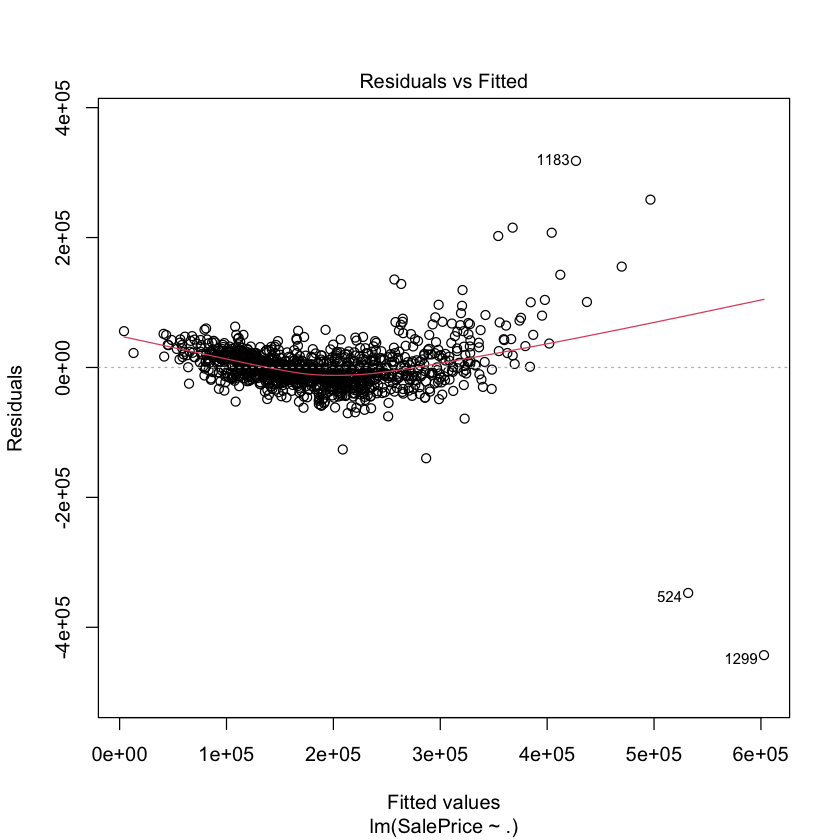

In [77]:
plot(model, which = 1)

based on these results, I would not trust the findings in case study one, as residuals vs fitted values does show spread when predicted values increase. The p-value of the shapiro test is below 0.05, so it suggests non-normality. THe Q-Q plot also does not hold here.